# Istanbul Traffic Analytics: Uzun Dönem Analizi

**Veri:** İBB Saatlik Trafik Yoğunluk Veri Seti, Ocak 2023 - Ocak 2025 (25 ay)
**Girdi:** ETL hattının ürettiği `data/processed/traffic_clean_YYYYMM.parquet` dosyaları

İlk notebook ([01_exploratory_analysis](01_exploratory_analysis.ipynb)) tek bir ayı inceledi. Bu notebook 25 ayın tamamına bakar ve beş soruya yanıt arar:

1. 25 ay boyunca veri ne kadar eksiksiz?
2. Şehrin hızı aylar içinde nasıl değişiyor, mevsimsellik var mı?
3. Ocak 2024'teki araç sayısı sıçraması ne zaman oldu ve neyi etkiliyor?
4. 2024'te akşam zirvesi gerçekten hızlandı mı, yoksa bu bir ağırlık etkisi mi?
5. Hücre düzeyinde hangi bölgeler yavaşladı, hangileri hızlandı?

Hesaplar pandas ile ham parquet dosyalarından yapılır. Son bölüm sonuçları PostgreSQL'deki SQL analizlerinin çıktılarıyla ([`docs/analysis-results`](../docs/analysis-results)) karşılaştırır. Herhangi bir fark notebook'u hata vererek durdurur.

**Yöntem notu:** Hız aykırıları ve kısmi saatler çıkarılır (`is_analysis_eligible`). Şehir geneli hızlar araç ağırlıklıdır. Akşam zirvesi hafta içi, resmî tatil olmayan günlerin 17:00-19:59 aralığıdır, gece 01:00-04:59 aralığıdır.

## 1. Kurulum

In [1]:
import logging
from datetime import timedelta
from pathlib import Path

import matplotlib as mpl
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.ticker import FuncFormatter

logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT
DATA_DIR = ROOT / "data" / "processed"
SQL_RESULTS = ROOT / "docs" / "analysis-results"
FIGURE_DIR = ROOT / "docs" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

SURFACE = "#fcfcfb"
INK = "#0b0b0b"
SECONDARY = "#52514e"
MUTED = "#898781"
GRID = "#e1e0d9"
AXIS = "#c3c2b7"
BLUE = "#2a78d6"
ORANGE = "#eb6834"
LIGHT_BLUE = "#b7d3f6"
SLOWER = "#e34948"
FASTER = "#3987e5"

SEQUENTIAL = LinearSegmentedColormap.from_list(
    "traffic_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
)
DIVERGING = LinearSegmentedColormap.from_list(
    "traffic_diverging", ["#8f2020", "#e34948", "#f0efec", "#3987e5", "#104281"]
)

mpl.rcParams.update({
    "figure.dpi": 100,
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "font.family": ["Segoe UI", "DejaVu Sans"],
    "font.size": 10,
    "text.color": INK,
    "axes.labelcolor": SECONDARY,
    "axes.edgecolor": AXIS,
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.7,
    "xtick.color": SECONDARY,
    "ytick.color": SECONDARY,
    "xtick.major.size": 0,
    "ytick.major.size": 0,
    "lines.linewidth": 2,
    "legend.frameon": False,
})
pd.set_option("display.width", 160)

MONTHS_TR = ["Oca", "Şub", "Mar", "Nis", "May", "Haz", "Tem", "Ağu", "Eyl", "Eki", "Kas", "Ara"]


def add_title(ax, title, subtitle):
    ax.set_title(title, loc="left", fontsize=13.5, fontweight="semibold", color=INK, pad=28)
    ax.text(0, 1.025, subtitle, transform=ax.transAxes, color=SECONDARY, fontsize=9.5, va="bottom")


def save(fig, name):
    fig.savefig(FIGURE_DIR / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.show()


def weighted(frame, by=None):
    """Vehicle-weighted speed: SUM(speed x vehicles) / SUM(vehicles)."""
    if by is None:
        return frame["speed_volume"].sum() / frame["vehicles"].sum()
    totals = frame.groupby(by, observed=True)[["speed_volume", "vehicles"]].sum()
    return totals["speed_volume"] / totals["vehicles"]


def month_label(period):
    return f"{MONTHS_TR[period.month - 1]} {str(period.year)[2:]}"

## 2. Veriyi yükleme

25 ay yaklaşık 40 milyon satırdır. Hepsini belleğe almak yerine her ay okunur ve iki özete indirgenir:

- **`city`**: Şehir geneli, saat başına bir satır. Araç sayısı, `hız × araç` toplamı ve veri gönderen hücre sayısı.
- **`cells`**: Hücre ve ay başına akşam zirvesi toplamları. Düşük örneklemli satırlar (`is_low_sample`) burada çıkarılır, veritabanındaki `agg_location_daily` tablosuyla aynı kural.

In [2]:
COLUMNS = [
    "observed_at", "geohash", "latitude", "longitude", "avg_speed_kmh", "vehicle_count",
    "is_weekend", "is_public_holiday", "is_low_sample", "is_analysis_eligible",
]

city_parts, cell_parts, locations, months = [], [], [], []
for path in sorted(DATA_DIR.glob("traffic_clean_*.parquet")):
    raw = pd.read_parquet(path, columns=COLUMNS)
    df = raw[raw["is_analysis_eligible"]].copy()
    df["speed_volume"] = df["avg_speed_kmh"].astype("int64") * df["vehicle_count"]
    hour = df["observed_at"].dt.hour

    city_parts.append(
        df.groupby("observed_at").agg(
            vehicles=("vehicle_count", "sum"),
            speed_volume=("speed_volume", "sum"),
            cells=("geohash", "size"),
            is_weekend=("is_weekend", "first"),
            is_holiday=("is_public_holiday", "any"),
        )
    )

    peak = df[~df["is_low_sample"] & ~df["is_weekend"] & ~df["is_public_holiday"] & hour.between(17, 19)]
    cell_parts.append(
        peak.groupby([peak["observed_at"].dt.to_period("M").rename("month"), "geohash"]).agg(
            vehicles=("vehicle_count", "sum"),
            speed_volume=("speed_volume", "sum"),
            hours=("vehicle_count", "size"),
        )
    )
    locations.append(raw.groupby("geohash")[["latitude", "longitude"]].first())
    months.append({"dosya": path.name, "satır": len(raw), "analize uygun": len(df)})

city = pd.concat(city_parts).reset_index()
city["month"] = city["observed_at"].dt.to_period("M")
city["date"] = city["observed_at"].dt.normalize()
city["hour"] = city["observed_at"].dt.hour
city["evening_peak"] = ~city["is_weekend"] & ~city["is_holiday"] & city["hour"].between(17, 19)
city["night"] = city["hour"].between(1, 4)

cells = pd.concat(cell_parts).reset_index()
locations = pd.concat(locations).groupby(level=0).first()

loaded = pd.DataFrame(months)
print(f"{len(loaded)} ay, {loaded['satır'].sum():,} satır, {loaded['analize uygun'].sum():,} analize uygun satır")
print(f"{len(city):,} saat, {locations.shape[0]:,} hücre")
loaded.iloc[[0, 1, 2, -3, -2, -1]]

25 ay, 40,087,669 satır, 39,627,138 analize uygun satır
16,721 saat, 2,464 hücre


,dosya,satır,analize uygun
0,traffic_clean_202301.parquet,1737740,1737694
1,traffic_clean_202302.parquet,1576068,1574521
2,traffic_clean_202303.parquet,1679947,1659248
22,traffic_clean_202411.parquet,1710138,1679399
23,traffic_clean_202412.parquet,1266396,1258075
24,traffic_clean_202501.parquet,1763963,1761615


## 3. Veri kapsamı

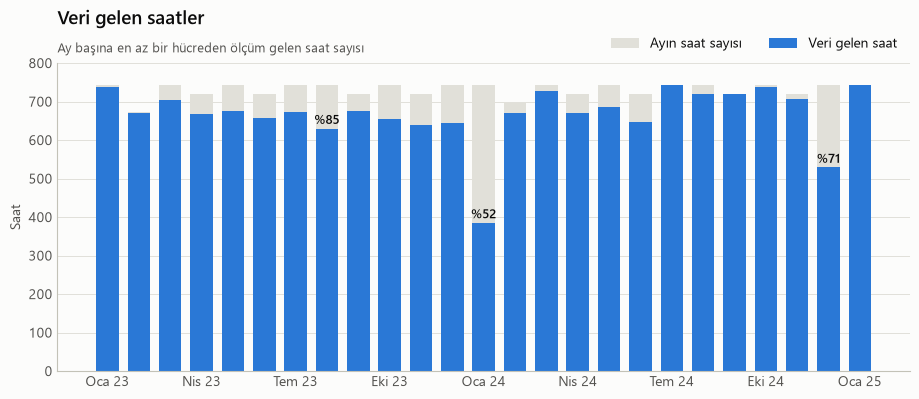

,hours,missing_hours
month,,
2023-08,630,114
2024-01,385,359
2024-12,529,215


In [3]:
coverage = city.groupby("month").agg(hours=("vehicles", lambda s: (s > 0).sum()), cells=("cells", "mean"))
coverage["days_in_month"] = coverage.index.days_in_month
coverage["missing_hours"] = coverage["days_in_month"] * 24 - coverage["hours"]

fig, ax = plt.subplots(figsize=(11, 4))
x = np.arange(len(coverage))
expected = coverage["days_in_month"] * 24
ax.bar(x, expected, color=GRID, width=0.72, label="Ayın saat sayısı")
ax.bar(x, coverage["hours"], color=BLUE, width=0.72, label="Veri gelen saat")
for i, (hours, total) in enumerate(zip(coverage["hours"], expected)):
    if hours / total < 0.85:
        ax.text(i, hours + 12, f"%{hours / total * 100:.0f}", ha="center", color=INK, fontsize=9, fontweight="semibold")
ax.set_xticks(x[::3], [month_label(p) for p in coverage.index[::3]])
ax.set_ylim(0, 800)
ax.set_ylabel("Saat")
ax.legend(loc="lower right", bbox_to_anchor=(1, 1.0), ncols=2)
ax.grid(axis="x", visible=False)
add_title(ax, "Veri gelen saatler", "Ay başına en az bir hücreden ölçüm gelen saat sayısı")
save(fig, "fig12_monthly_coverage")

coverage.loc[coverage["missing_hours"] > 100, ["hours", "missing_hours"]]

**Yorum**

- 25 ayda 40,1 milyon satır var, bunların %98,9'u analize uygun. Diğer ayların hepsinde saatlerin en az %86'sında veri var.
- Üç ay belirgin eksik: Ağustos 2023 (%85), Aralık 2024 (%71) ve en çok Ocak 2024 (%52, 359 saat eksik). Ocak 2024'teki boşluk, bir sonraki bölümdeki sayım kırılmasının hemen öncesine denk gelir.
- Eksik saatler sıfır araçla doldurulmaz. Bu yüzden aylar toplam araçla değil, hücre ve saat başına ortalama araçla karşılaştırılır.

## 4. Aylık trend

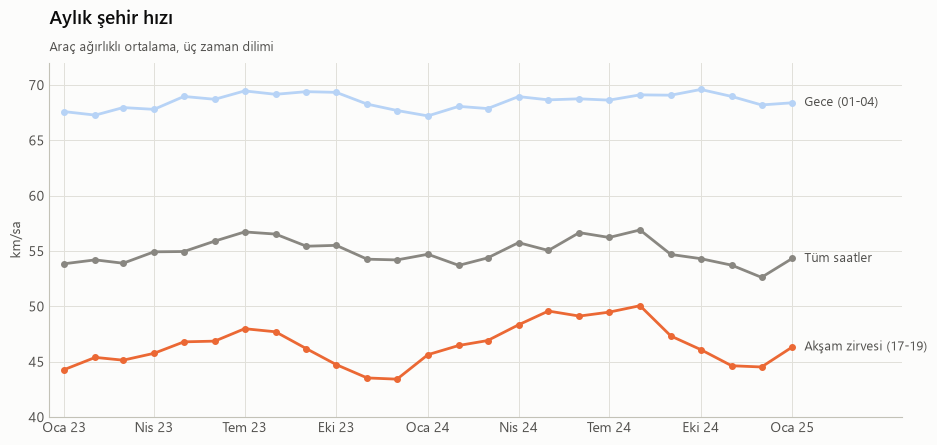

month,2023-01,2023-07,2024-01,2024-07,2025-01
speed,53.86,56.73,54.71,56.23,54.34
evening_peak,44.30,47.99,45.64,49.48,46.34
night,67.60,69.47,67.21,68.64,68.40
vehicles_per_cell_hour,72.66,67.70,84.51,109.37,89.05


In [4]:
monthly = pd.DataFrame({
    "speed": weighted(city, "month"),
    "evening_peak": weighted(city[city["evening_peak"]], "month"),
    "night": weighted(city[city["night"]], "month"),
    "vehicles_per_cell_hour": city.groupby("month")["vehicles"].sum() / city.groupby("month")["cells"].sum(),
})

fig, ax = plt.subplots(figsize=(11, 4.6))
dates = list(monthly.index.to_timestamp().to_pydatetime())
series = [("night", "Gece (01-04)", LIGHT_BLUE), ("speed", "Tüm saatler", MUTED), ("evening_peak", "Akşam zirvesi (17-19)", ORANGE)]
for column, label, color in series:
    ax.plot(dates, monthly[column], color=color, marker="o", markersize=4)
    ax.text(dates[-1] + timedelta(days=12), monthly[column].iloc[-1], label, color=SECONDARY, va="center", fontsize=9)
ax.set_ylim(40, 72)
ax.set_ylabel("km/sa")
ax.set_xlim(dates[0] - timedelta(days=15), dates[-1] + timedelta(days=110))
ax.set_xticks(dates[::3], [month_label(p) for p in monthly.index[::3]])
add_title(ax, "Aylık şehir hızı", "Araç ağırlıklı ortalama, üç zaman dilimi")
save(fig, "fig13_monthly_speed")

monthly.round(2).T.iloc[:, [0, 6, 12, 18, 24]]

**Yorum**

- Gece hızı 25 ay boyunca 67-70 km/sa bandında kalır. Serbest akış hızı değişmediği için ölçüm yönteminin hızı etkileyen bir değişiklik geçirmediği söylenebilir.
- Akşam zirvesi belirgin bir yıllık döngü izler: yazın en hızlı (Temmuz 2023'te 48,0, Ağustos 2024'te 50,1 km/sa), Aralık'ta en yavaştır (43,4 ve 44,5 km/sa).
- Hücre-saat başına araç 2023'te 61-78 arasındayken Şubat 2024'ten itibaren 100-131 aralığındadır. Hızda buna karşılık gelen bir düşüş yoktur.

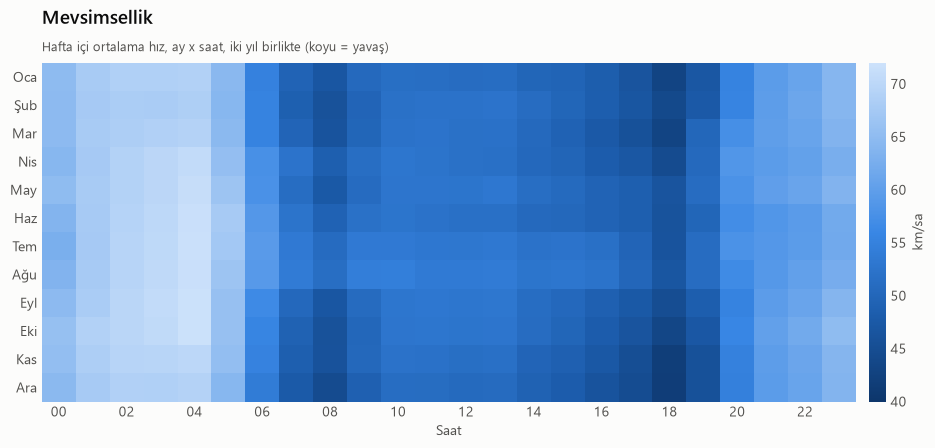

Akşam zirvesi Temmuz-Ağustos: 49.2 km/sa, Ekim-Aralık: 44.7 km/sa


In [5]:
weekday = city[~city["is_weekend"] & ~city["is_holiday"]].copy()
weekday["calendar_month"] = weekday["observed_at"].dt.month
season = weighted(weekday, ["calendar_month", "hour"]).unstack()

fig, ax = plt.subplots(figsize=(11, 4.4))
image = ax.imshow(season, aspect="auto", cmap=SEQUENTIAL.reversed(), vmin=40, vmax=72)
ax.set_yticks(range(12), MONTHS_TR)
ax.set_xticks(range(0, 24, 2), [f"{h:02d}" for h in range(0, 24, 2)])
ax.set_xlabel("Saat")
ax.grid(False)
for spine in ax.spines.values():
    spine.set_visible(False)
bar = fig.colorbar(image, ax=ax, pad=0.015, fraction=0.03)
bar.set_label("km/sa", color=SECONDARY)
bar.outline.set_visible(False)
add_title(ax, "Mevsimsellik", "Hafta içi ortalama hız, ay x saat, iki yıl birlikte (koyu = yavaş)")
save(fig, "fig14_seasonality")

summer = season.loc[[7, 8], 17:19].stack().mean()
autumn = season.loc[[10, 11, 12], 17:19].stack().mean()
print(f"Akşam zirvesi Temmuz-Ağustos: {summer:.1f} km/sa, Ekim-Aralık: {autumn:.1f} km/sa")

**Yorum**

- Günün en yavaş saati her ay 18:00'dir. Sabah zirvesi 08:00'de, akşamınkinden daha kısa ve daha hafiftir.
- Hafta içi akşam zirvesi Temmuz-Ağustos'ta 49,2 km/sa, Ekim-Aralık'ta 44,7 km/sa'tir. Fark yaklaşık 4,5 km/sa'tir.
- Temmuz ve Ağustos'ta sabah zirvesi belirgin şekilde hafifler. Bu, okul tatilinin sabah trafiğine etkisiyle tutarlıdır.

## 5. Araç sayımındaki kırılma

Hücre ve saat başına ortalama araç sayısı Şubat 2024'ten itibaren belirgin şekilde yüksektir. Aylık seri kırılmanın yalnızca ayını gösterir, günlük seri tarihini bulmayı sağlar. Seri iki düz seviyeye bölünür ve hatayı en aza indiren bölme noktası kırılma tarihi kabul edilir (tek kırılma noktalı en küçük kareler). Hafta sonları ve tatiller sayıyı doğal olarak düşürdüğü için yalnızca en az 20 saati ölçülmüş normal iş günleri kullanılır.

Kırılma tarihi: 24.01.2024 (önceki iş günü 10.01.2024)
İş günü medyanı: 73.2 → 122.6 araç (x1.68)


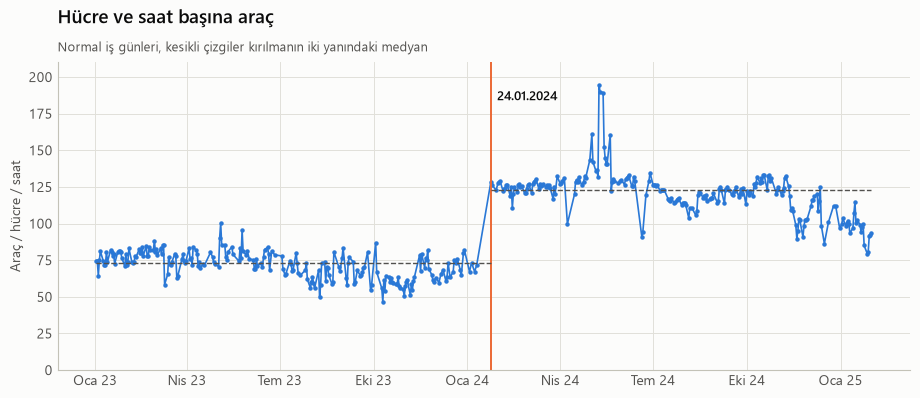

In [6]:
daily = city.groupby("date").agg(
    vehicles=("vehicles", "sum"), cells=("cells", "sum"), hours=("hour", "size"),
    is_weekend=("is_weekend", "first"), is_holiday=("is_holiday", "any"),
)
daily["per_cell_hour"] = daily["vehicles"] / daily["cells"]
workdays = daily[~daily["is_weekend"] & ~daily["is_holiday"] & (daily["hours"] >= 20)]["per_cell_hour"]

values = np.log(workdays.to_numpy())
errors = [
    ((values[:k] - values[:k].mean()) ** 2).sum() + ((values[k:] - values[k:].mean()) ** 2).sum()
    for k in range(10, len(values) - 10)
]
split = 10 + int(np.argmin(errors))
break_date = workdays.index[split]
level_before = workdays.iloc[:split].median()
level_after = workdays.iloc[split:].median()
print(f"Kırılma tarihi: {break_date:%d.%m.%Y} (önceki iş günü {workdays.index[split - 1]:%d.%m.%Y})")
print(f"İş günü medyanı: {level_before:.1f} → {level_after:.1f} araç (x{level_after / level_before:.2f})")

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(workdays.index, workdays, color=BLUE, linewidth=1.2, marker="o", markersize=2.2)
ax.axvline(break_date, color=ORANGE, linewidth=1.4)
ax.text(break_date.to_pydatetime() + timedelta(days=6), workdays.max() * 0.98, f"{break_date:%d.%m.%Y}", color=INK, fontsize=9.5, fontweight="semibold", va="top")
for start, end, level in [(workdays.index[0], break_date, level_before), (break_date, workdays.index[-1], level_after)]:
    ax.hlines(level, start, end, color=SECONDARY, linewidth=1, linestyles="--")
ax.set_ylim(0, workdays.max() * 1.08)
ax.set_ylabel("Araç / hücre / saat")
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: month_label(pd.Period(mdates.num2date(v), "M"))))
add_title(ax, "Hücre ve saat başına araç", "Normal iş günleri, kesikli çizgiler kırılmanın iki yanındaki medyan")
save(fig, "fig15_volume_break")

**Yorum**

- Kırılma 24 Ocak 2024'tedir. Ölçümü tam olan bir önceki iş günü 10 Ocak'tır, aradaki günlerde veri eksiktir.
- İş günü medyanı hücre-saat başına 73,2 araçtan 122,6 araca çıkar (1,68 kat) ve bu seviyede kalır. Gerçek trafiğin bir günde bu kadar artması mümkün değildir, hız serisinde de karşılığı yoktur. Bu, İBB'nin araç sayım yöntemindeki bir değişikliğe işaret eder.
- Mayıs 2024'te birkaç günlük ikinci bir sıçrama (190 araca kadar) görülür, ardından seri eski seviyesine döner. Bunun açıklaması veride yoktur.
- **Sonuç:** Bu tarihin iki yanı arasında hacim karşılaştırılmamalıdır. Bir sonraki bölüm, kırılmanın araç ağırlıklı hız karşılaştırmalarını da etkilediğini gösterir.

## 6. 2024'te akşam zirvesi gerçekten hızlandı mı?

SQL analizi her ay için hafta içi akşam zirvesini bir önceki yılın aynı ayıyla karşılaştırır: araç ağırlıklı şehir ortalaması 2024'ün 12 ayının hepsinde daha hızlıdır. Fakat ağırlıklar araç sayısıdır ve araç sayımı Ocak 2024'te değişti. Sayım her hücrede aynı oranda artmadıysa ağırlıklar yer değiştirir. Ortalama, hiçbir hücre hızlanmasa bile yükselebilir.

Bunu ayırmak için aynı karşılaştırma iki ağırlıktan bağımsız ölçüyle tekrarlanır:

- **Sabit ağırlık:** Her hücrenin kendi akşam hızı, kırılmadan önceki 2023 yılındaki araç payıyla ağırlıklandırılır. Ağırlıklar iki yılda aynıdır.
- **Medyan hücre:** Her hücreye eşit ağırlık.

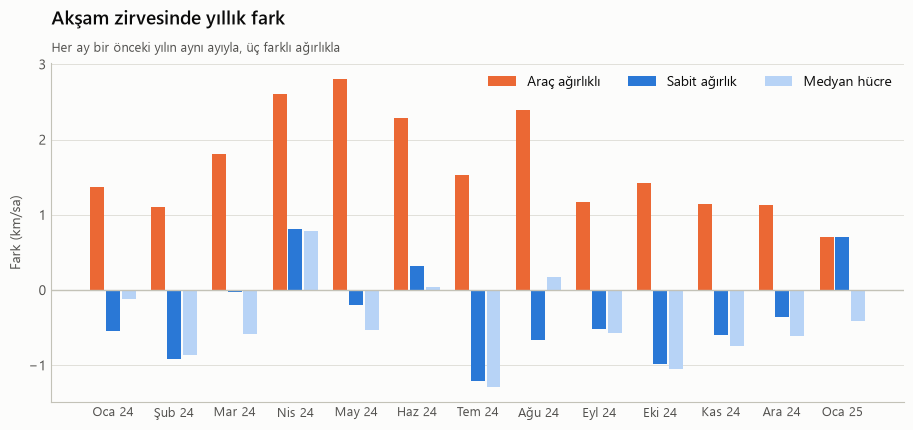

,mean,min,max,daha hızlı ay
araç ağırlıklı,1.65,0.70,2.81,13
sabit ağırlık,-0.32,-1.20,0.81,3
medyan hücre,-0.44,-1.28,0.79,3


In [7]:
cells["speed"] = cells["speed_volume"] / cells["vehicles"]
baseline = cells[cells["month"] < pd.Period("2024-01", "M")].groupby("geohash")["vehicles"].sum()
cells["base_weight"] = cells["geohash"].map(baseline / baseline.sum()).fillna(0)

by_month = cells.groupby("month").apply(
    lambda f: pd.Series({
        "araç ağırlıklı": f["speed_volume"].sum() / f["vehicles"].sum(),
        "sabit ağırlık": np.average(f["speed"], weights=f["base_weight"]),
        "medyan hücre": f["speed"].median(),
    }),
    include_groups=False,
)
yoy = (by_month - by_month.shift(12)).dropna()
yoy.index = [month_label(p) for p in yoy.index]

fig, ax = plt.subplots(figsize=(11, 4.4))
x = np.arange(len(yoy))
width = 0.26
for offset, (column, color) in zip([-width, 0, width], [("araç ağırlıklı", ORANGE), ("sabit ağırlık", BLUE), ("medyan hücre", LIGHT_BLUE)]):
    ax.bar(x + offset, yoy[column], width=width - 0.03, color=color, label=column.capitalize())
ax.axhline(0, color=AXIS, linewidth=1)
ax.set_xticks(x, yoy.index, fontsize=9)
ax.set_ylabel("Fark (km/sa)")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right", ncols=3)
add_title(ax, "Akşam zirvesinde yıllık fark", "Her ay bir önceki yılın aynı ayıyla, üç farklı ağırlıkla")
save(fig, "fig16_yoy_weighting")

summary = yoy.agg(["mean", "min", "max"]).T
summary["daha hızlı ay"] = (yoy > 0).sum()
summary.round(2)

**Yorum**

- Araç ağırlıklı ortalamaya göre akşam zirvesi karşılaştırılan 13 ayın hepsinde hızlanmıştır, ortalama +1,65 km/sa.
- Ağırlıklar sabitlendiğinde tablo değişir: ortalama fark -0,32 km/sa'tir ve 13 ayın yalnızca 3'ünde hızlanma vardır. Medyan hücre de aynı sonucu verir (-0,44 km/sa, 3 ay).
- Yani şehir ortalamasındaki hızlanmanın büyük kısmı hücrelerin hızlanmasından değil, sayım değişikliğinin ağırlıkları hızlı yollara kaydırmasından gelir. Sayım artışı otoyol gibi hızlı hücrelerde daha büyük olduysa bu hücrelerin ortalamadaki payı büyür ve ortalama yükselir.
- **Sonuç:** "2024'te akşam trafiği rahatladı" demek için araç ağırlıklı ortalama tek başına yeterli değildir. Hücrelerin kendi geçmişiyle karşılaştırılması daha güvenilir bir ölçüdür.

## 7. Hücre bazında değişim

Her hücre kendisiyle karşılaştırılır: son 12 ayın (Şubat 2024 - Ocak 2025) akşam zirvesi hızı, önceki 12 ayınkiyle (Şubat 2023 - Ocak 2024). Her iki dönemde de en çok ölçümü olan hücrenin en az yarısı kadar akşam saati olan hücreler karşılaştırılır. Bu, SQL'deki `17_location_change` sorgusunun kuralıdır.

Karşılaştırılan hücre: 2,240
Ortalama fark -0.36 km/sa, medyan -0.23 km/sa
1 km/sa'ten fazla yavaşlayan %28.5, hızlanan %17.3


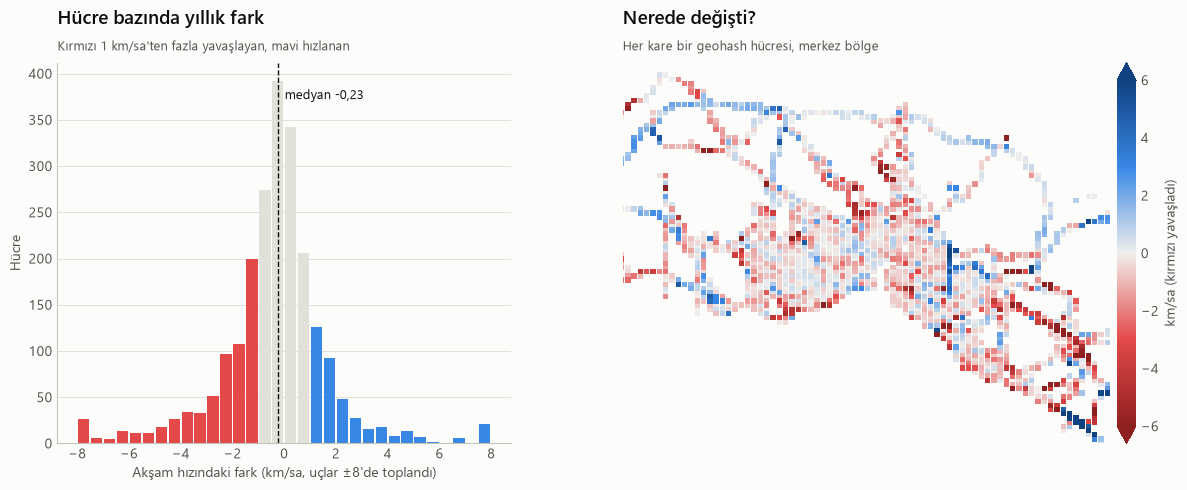

In [8]:
window = cells[cells["month"] >= pd.Period("2023-02", "M")].copy()
window["period"] = np.where(window["month"] >= pd.Period("2024-02", "M"), "current", "previous")
totals = window.groupby(["geohash", "period"])[["speed_volume", "vehicles", "hours"]].sum().unstack()
speed = totals["speed_volume"] / totals["vehicles"]
hours = totals["hours"]
covered = (hours["current"] >= 0.5 * hours["current"].max()) & (hours["previous"] >= 0.5 * hours["previous"].max())

change = (speed["current"] - speed["previous"])[covered].rename("change")
cell_change = locations.join(change, how="inner").join(speed["previous"].rename("previous_speed"))

print(f"Karşılaştırılan hücre: {len(change):,}")
print(f"Ortalama fark {change.mean():+.2f} km/sa, medyan {change.median():+.2f} km/sa")
print(f"1 km/sa'ten fazla yavaşlayan %{(change < -1).mean() * 100:.1f}, hızlanan %{(change > 1).mean() * 100:.1f}")

fig, (left, right) = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={"width_ratios": [1, 1.35]})
bins = np.arange(-8, 8.5, 0.5)
counts, edges = np.histogram(change.clip(-8, 8), bins=bins)
centers = (edges[:-1] + edges[1:]) / 2
colors = [SLOWER if c < -1 else FASTER if c > 1 else GRID for c in centers]
left.bar(centers, counts, width=0.44, color=colors)
left.axvline(change.median(), color=INK, linewidth=1, linestyle="--")
left.text(change.median() + 0.25, counts.max() * 0.95, f"medyan {change.median():+.2f}".replace(".", ","), fontsize=9, color=INK)
left.set_xlabel("Akşam hızındaki fark (km/sa, uçlar ±8'de toplandı)")
left.set_ylabel("Hücre")
left.grid(axis="x", visible=False)
add_title(left, "Hücre bazında yıllık fark", "Kırmızı 1 km/sa'ten fazla yavaşlayan, mavi hızlanan")

norm = TwoSlopeNorm(vmin=-6, vcenter=0, vmax=6)
ordered = cell_change.reindex(cell_change["change"].abs().sort_values().index)
points = right.scatter(ordered["longitude"], ordered["latitude"], c=ordered["change"], cmap=DIVERGING, norm=norm, s=15, marker="s", linewidths=0)
right.set_aspect(1 / np.cos(np.radians(41.0)))
right.set_xlim(28.55, 29.4)
right.set_ylim(40.8, 41.3)
right.grid(False)
right.set_xticks([])
right.set_yticks([])
for spine in right.spines.values():
    spine.set_visible(False)
bar = fig.colorbar(points, ax=right, pad=0.01, fraction=0.035, extend="both")
bar.set_label("km/sa (kırmızı yavaşladı)", color=SECONDARY)
bar.outline.set_visible(False)
add_title(right, "Nerede değişti?", "Her kare bir geohash hücresi, merkez bölge")
fig.tight_layout()
save(fig, "fig17_cell_change")

In [9]:
bands = pd.qcut(cell_change["previous_speed"], 5)
by_band = cell_change.groupby(bands, observed=True)["change"].agg(
    hücre="size",
    medyan_fark="median",
    yavaşlayan_pay=lambda s: (s < -1).mean() * 100,
)
by_band.index = [f"{b.left:.0f}-{b.right:.0f} km/sa" for b in by_band.index]
by_band.index.name = "önceki yıl akşam hızı"
by_band.round(2)

,hücre,medyan_fark,yavaşlayan_pay
önceki yıl akşam hızı,,,
11-25 km/sa,448,-0.13,7.37
25-35 km/sa,448,-0.41,30.36
35-54 km/sa,448,-0.79,43.53
54-85 km/sa,448,-0.71,44.64
85-112 km/sa,448,0.56,16.74


**Yorum**

- 2.240 hücre karşılaştırıldı. Ortalama fark -0,36 km/sa, medyan fark -0,23 km/sa'tir. Hücrelerin %28,5'i 1 km/sa'ten fazla yavaşlarken %17,3'ü hızlanmıştır.
- Değişim önceki hıza göre farklılaşır. Akşam hızı 35-85 km/sa olan ana arter hücrelerinin %44'ü yavaşlamıştır (medyan -0,7 ile -0,8 km/sa). Zaten en yavaş olan merkez hücreler (11-25 km/sa) neredeyse yerinde sayar, en hızlı otoyol hücreleri (85 km/sa üstü) ise +0,56 km/sa hızlanmıştır.
- Haritada yavaşlama tek bir bölgede toplanmaz. Aynı aks üzerinde yavaşlayan ve hızlanan hücreler yan yana görülebilir, bu da değişimin bölgeden çok yol tipine bağlı olduğunu düşündürür.

## 8. SQL sonuçlarıyla doğrulama

Aynı göstergeler veritabanında SQL ile ([`database/analysis`](../database/analysis)) hesaplanmıştı. Buradaki pandas hesapları ham parquet dosyalarından, veritabanına hiç dokunmadan yapıldı. İki yolun sonuçları yuvarlama payı içinde eşleşmelidir.

In [10]:
results = []


def check(name, actual, expected, tolerance):
    actual, expected = np.asarray(actual, dtype=float), np.asarray(expected, dtype=float)
    difference = float(np.nanmax(np.abs(actual - expected)))
    results.append({"kontrol": name, "değer sayısı": actual.size, "en büyük fark": round(difference, 4), "sonuç": "geçti" if difference <= tolerance else "HATA"})


sql_monthly = pd.read_csv(SQL_RESULTS / "14_monthly_trend.csv", parse_dates=["month"])
sql_monthly.index = sql_monthly["month"].dt.to_period("M")
check("Aylık ağırlıklı hız (14)", monthly["speed"], sql_monthly["weighted_speed_kmh"], 0.006)
check("Aylık akşam zirvesi (14)", monthly["evening_peak"], sql_monthly["evening_peak_speed_kmh"], 0.006)
check("Aylık gece hızı (14)", monthly["night"], sql_monthly["night_speed_kmh"], 0.006)
check("Hücre-saat başına araç (14)", monthly["vehicles_per_cell_hour"], sql_monthly["vehicles_per_cell_hour"], 0.06)
check("Veri gelen saat (14)", coverage["hours"], sql_monthly["observed_hours"], 0)

sql_yoy = pd.read_csv(SQL_RESULTS / "15_year_over_year.csv").dropna()
city_yoy = (monthly["evening_peak"] - monthly["evening_peak"].shift(12)).dropna()
check("Yıllık fark (15)", city_yoy, sql_yoy["change_kmh"], 0.011)

sql_cells = pd.read_csv(SQL_RESULTS / "17_location_change.csv").iloc[0]
check("Karşılaştırılan hücre (17)", len(change), sql_cells["compared_cells"], 0)
check("Ortalama hücre farkı (17)", change.mean(), sql_cells["mean_change_kmh"], 0.006)
check("Medyan hücre farkı (17)", change.median(), sql_cells["median_change_kmh"], 0.006)
check("Yavaşlayan hücre payı (17)", (change < -1).mean() * 100, sql_cells["slower_share_pct"], 0.06)
check("Hızlanan hücre payı (17)", (change > 1).mean() * 100, sql_cells["faster_share_pct"], 0.06)

report = pd.DataFrame(results)
assert (report["sonuç"] == "geçti").all(), report[report["sonuç"] != "geçti"]
report

,kontrol,değer sayısı,en büyük fark,sonuç
0,Aylık ağırlıklı hız (14),25,0.0046,geçti
1,Aylık akşam zirvesi (14),25,0.0048,geçti
2,Aylık gece hızı (14),25,0.0045,geçti
3,Hücre-saat başına araç (14),25,0.0474,geçti
4,Veri gelen saat (14),25,0.0000,geçti
5,Yıllık fark (15),13,0.0044,geçti
6,Karşılaştırılan hücre (17),1,0.0000,geçti
7,Ortalama hücre farkı (17),1,0.0025,geçti
8,Medyan hücre farkı (17),1,0.0011,geçti
9,Yavaşlayan hücre payı (17),1,0.0268,geçti


## 9. Sonuçlar

| Bulgu | Sayı | Sonucu |
|---|---|---|
| Veri kapsamı yüksek, üç ay eksik | Ocak 2024'te saatlerin %52'si | Eksik saatler doldurulmaz, hacim hücre-saat başına karşılaştırılır |
| Akşam zirvesinin yıllık döngüsü var | Yaz 49,2, kış 44,7 km/sa | Aylar yalnızca bir önceki yılın aynı ayıyla karşılaştırılır |
| Araç sayımı 24 Ocak 2024'te değişti | 73,2 → 122,6 araç (x1,68) | Kırılmanın iki yanı arasında hacim karşılaştırılmaz |
| Şehir ortalamasındaki hızlanma büyük ölçüde ağırlık etkisi | +1,65 yerine -0,32 km/sa (sabit ağırlık) | Değişim hücre bazında, her hücre kendi geçmişiyle ölçülür |
| Ana arterler yavaşladı, otoyollar hızlandı | Arterlerin %44'ü yavaşladı | Bölgesel değişim haritası dashboard'da ayrıca gösterilir |

Python ile ham dosyalardan yapılan hesaplar, PostgreSQL'deki SQL analizlerinin 11 göstergesiyle yuvarlama payı içinde eşleşti. Aynı sonuca iki bağımsız yoldan ulaşılması, hem ETL'in hem de özet katmanın doğru çalıştığını gösterir.